In [1]:
import json, random, hashlib
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from PIL import Image
import torch

DATA_ROOT = Path("../data")   # train.csv, val.csv, test.csv, images/, kart json'u burada olmalı
card = json.load(open(next(DATA_ROOT.glob("*card*.json"))))

SEED = card["seed"]
CLASS_NAMES = card["classes"]
NUM_CLASSES = len(CLASS_NAMES)

def seed_all(s=SEED):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
seed_all()

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", DEVICE, "| seed:", SEED, "| sınıf sayısı:", NUM_CLASSES)

Device: cuda | seed: 20261019 | sınıf sayısı: 9


In [2]:
dfs = []
for s in ["train", "val", "test"]:
    d = pd.read_csv(DATA_ROOT/f"{s}.csv"); d["split"] = s; dfs.append(d)
df = pd.concat(dfs, ignore_index=True)
print(df.columns.tolist()); print(df.head(3))

def pick(cols, cands):
    return next((c for c in cands if c in cols), None)

path_col  = pick(df.columns, ["path","filepath","file_path","image_path","image","filename","file_name","id"])
label_col = pick(df.columns, ["label","y","class","target","class_id","species","category"])
assert path_col and label_col, f"Sütunlar tanınmadı: {df.columns.tolist()}"
print("yol sütunu:", path_col, "| etiket sütunu:", label_col)

IMG_DIR = DATA_ROOT/"images"
def resolve(p):
    p = str(p)
    for c in [Path(p), DATA_ROOT/p, IMG_DIR/p, IMG_DIR/Path(p).name]:
        if c.exists(): return str(c)
    return None
df["path"] = df[path_col].map(resolve)
assert df.path.isna().sum() == 0, f"Bulunamayan görsel: {df.path.isna().sum()}"

if df[label_col].dtype == object:
    df["y"] = df[label_col].map({c:i for i,c in enumerate(CLASS_NAMES)})
else:
    df["y"] = df[label_col]

for s, n in card["counts"].items():
    assert (df.split==s).sum() == n, f"{s}: beklenen {n}, bulunan {(df.split==s).sum()}"
for s in ["train", "val"]:
    got = df[df.split==s].y.astype(int).value_counts().to_dict()
    exp = {int(k):v for k,v in card["class_counts"][s].items()}
    assert got == exp, f"{s} sınıf sayıları kartla uyuşmuyor"
print("Kart ile doğrulama OK")
print("Test etiket doluluğu:", df[df.split=="test"].y.notna().mean())

['id', 'path', 'label', 'group_id', 'source_id', 'sha256', 'split']
          id                  path  label    group_id              source_id  \
0  T03_00000  images/T03_00000.jpg    0.0  20160928_0  20160928-140314-0.jpg   
1  T03_00001  images/T03_00001.jpg    0.0  20160928_0  20160928-140337-0.jpg   
2  T03_00002  images/T03_00002.jpg    0.0  20160928_0  20160928-140731-0.jpg   

                                              sha256  split  
0  27027cb6d4a68a298f70c1b650541461d6dc5345cdb3f6...  train  
1  f59b22345665c84dc3efade60b07fef6a3c2b8b559fe5f...  train  
2  3886f6d831cb27a90bdb45f9bde11bcdf7ef3aa5a490d9...  train  
yol sütunu: path | etiket sütunu: label
Kart ile doğrulama OK
Test etiket doluluğu: 0.0


C:\Users\burak\AppData\Local\Temp\ipykernel_6940\2014770550.py:30: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\torch\csrc\utils\tensor_numpy.cpp:209.)
  ytr = torch.from_numpy(tr.y.astype(np.int64).values)


yüklendi: 41s | train (12109, 256, 256, 3) 2.38 GB
batch: (64, 3, 160, 160) torch.float32 | mean=-0.350 std=0.995


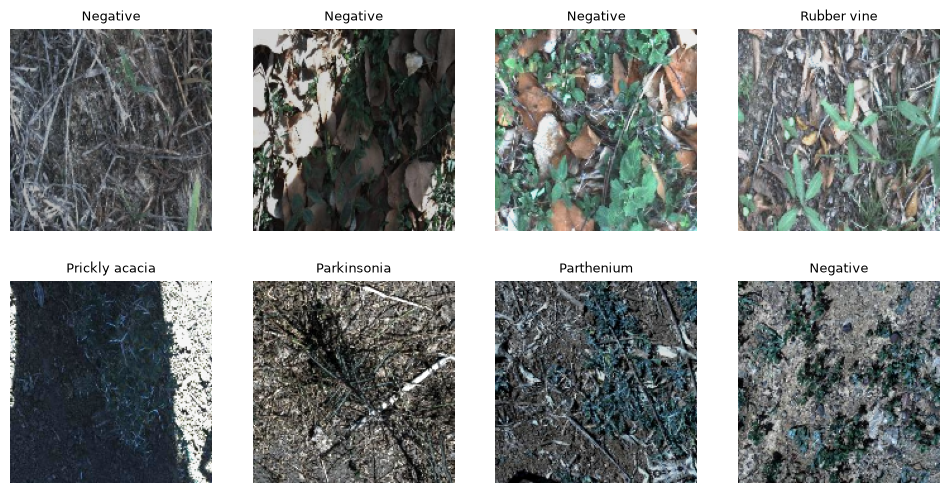

veri hattı hızı (160px): 955 görsel/sn


In [4]:
# ---------- Hücre 6 (BİRLEŞİK): önbellek + GPU augment + hızlı loader ----------
import os, math, time
from concurrent.futures import ThreadPoolExecutor
import torch.nn.functional as F

IMG, BS = 256, 64                    # disk önbellek çözünürlüğü; eğitim boyutu bundan bağımsız
MEAN, STD = (0.485,0.456,0.406), (0.229,0.224,0.225)
torch.backends.cudnn.benchmark = True
seed_all()
Path("../outputs").mkdir(exist_ok=True)

tr, va, te = (df[df.split == s] for s in ["train", "val", "test"])

# ---- 1) Görselleri bir kez uint8 diziye yükle (disk cache'li) ----
def load_split(d, name):
    f = Path(f"../outputs/cache_{name}_{len(d)}_{IMG}.npy")
    if f.exists(): return np.load(f)
    paths = d.path.values
    arr = np.empty((len(d), IMG, IMG, 3), np.uint8)
    def rd(i):
        im = Image.open(paths[i]).convert("RGB")
        if im.size != (IMG, IMG): im = im.resize((IMG, IMG), Image.BILINEAR)
        arr[i] = np.asarray(im)
    with ThreadPoolExecutor(min(16, (os.cpu_count() or 4) * 2)) as ex:
        list(ex.map(rd, range(len(d))))
    np.save(f, arr); return arr

t0 = time.time()
Xtr, Xva, Xte = (torch.from_numpy(load_split(d, n)) for d, n in [(tr,"train"),(va,"val"),(te,"test")])
ytr = torch.from_numpy(tr.y.astype(np.int64).values)
yva = torch.from_numpy(va.y.astype(np.int64).values)
yte = torch.full((len(te),), -1, dtype=torch.int64)
print(f"yüklendi: {time.time()-t0:.0f}s | train {tuple(Xtr.shape)} {Xtr.nbytes/1e9:.2f} GB")

# ---- 2) GPU augment (size parametreli) + eval ön işleme ----
_mean = torch.tensor(MEAN, device=DEVICE).view(1,3,1,1)
_std  = torch.tensor(STD,  device=DEVICE).view(1,3,1,1)
def _u(B, lo, hi): return torch.empty(B, device=DEVICE).uniform_(lo, hi)

def prep_eval(xb, size=224):
    x = xb.float().div_(255)
    if x.shape[-1] != size:
        x = F.interpolate(x, size=(size,size), mode="bilinear", align_corners=False, antialias=True)
    return ((x - _mean) / _std).contiguous(memory_format=torch.channels_last)

@torch.no_grad()
def gpu_augment(xb, size=224):
    """(B,3,H,W) GPU'da → RRC + flip + rotasyon (tek affine) + renk jitter → size×size, normalize."""
    B = xb.size(0)
    x = xb.float().div_(255)
    area  = _u(B, 0.6, 1.0)
    ratio = torch.exp(_u(B, math.log(3/4), math.log(4/3)))
    sx = torch.sqrt(area * ratio).clamp(max=1.0)
    sy = torch.sqrt(area / ratio).clamp(max=1.0)
    cx = (torch.rand(B, device=DEVICE) * 2 - 1) * (1 - sx)
    cy = (torch.rand(B, device=DEVICE) * 2 - 1) * (1 - sy)
    ang = _u(B, -20, 20) * math.pi / 180
    fh = (torch.rand(B, device=DEVICE) < 0.5).float() * 2 - 1
    fv = (torch.rand(B, device=DEVICE) < 0.5).float() * 2 - 1
    cos, sin = torch.cos(ang), torch.sin(ang)
    theta = torch.stack([torch.stack([cos*sx*fh, -sin*sy*fv, cx], 1),
                         torch.stack([sin*sx*fh,  cos*sy*fv, cy], 1)], 1)   # (B,2,3)
    grid = F.affine_grid(theta, (B, 3, size, size), align_corners=False)
    x = F.grid_sample(x, grid, mode="bilinear", padding_mode="reflection", align_corners=False)
    x = (x * _u(B, 0.7, 1.3).view(B,1,1,1)).clamp_(0, 1)                       # parlaklık
    m = x.mean(dim=(1,2,3), keepdim=True)
    x = ((x - m) * _u(B, 0.7, 1.3).view(B,1,1,1) + m).clamp_(0, 1)             # kontrast
    g = 0.299*x[:,0:1] + 0.587*x[:,1:2] + 0.114*x[:,2:3]
    x = ((x - g) * _u(B, 0.75, 1.25).view(B,1,1,1) + g).clamp_(0, 1)           # doygunluk
    return ((x - _mean) / _std).contiguous(memory_format=torch.channels_last)

# ---- 3) Worker'sız loader (on_gpu + size destekli) ----
class FastLoader:
    def __init__(self, X, y, bs, train=False, on_gpu=False, size=224):
        self.X = X if torch.is_tensor(X) else torch.as_tensor(np.asarray(X))
        self.y = (y if torch.is_tensor(y) else torch.as_tensor(np.asarray(y))).long()
        self.bs, self.train, self.size, self.on_gpu = bs, train, size, on_gpu
        self.n = self.y.numel()
        if on_gpu: self.X, self.y = self.X.to(DEVICE), self.y.to(DEVICE)
    def __len__(self):
        return self.n // self.bs if self.train else math.ceil(self.n / self.bs)  # train: drop_last
    def __iter__(self):
        idx = torch.randperm(self.n, device=self.X.device) if self.train \
              else torch.arange(self.n, device=self.X.device)
        for i in range(len(self)):
            j = idx[i*self.bs:(i+1)*self.bs]
            xb, yb = self.X[j], self.y[j]
            if not self.on_gpu:
                xb = xb.to(DEVICE, non_blocking=True); yb = yb.to(DEVICE, non_blocking=True)
            if xb.shape[1] not in (1,3) and xb.shape[-1] in (1,3):
                xb = xb.permute(0,3,1,2)               # NHWC → NCHW
            xb = gpu_augment(xb, self.size) if self.train else prep_eval(xb, self.size)
            yield xb, yb

test_dl = FastLoader(Xte, yte, BS, train=False, size=224)

# ---- 4) Kontroller ----
_tmp = FastLoader(Xtr, ytr, BS, train=True, size=160)
xb, yb = next(iter(_tmp))
print("batch:", tuple(xb.shape), xb.dtype, f"| mean={xb.mean():.3f} std={xb.std():.3f}")

img = (xb[:8].float().cpu() * torch.tensor(STD).view(1,3,1,1) + torch.tensor(MEAN).view(1,3,1,1)).clamp(0,1)
fig, ax = plt.subplots(2, 4, figsize=(12, 6))
for a, im, l in zip(ax.flat, img, yb[:8].cpu()):
    a.imshow(im.permute(1,2,0)); a.set_title(CLASS_NAMES[l], fontsize=9); a.axis("off")
plt.show()

def bench(dl, n=30):
    if DEVICE == "cuda": torch.cuda.synchronize()
    t, k = time.time(), 0
    for i, (xb, _) in enumerate(dl):
        k += len(xb)
        if i + 1 == n: break
    if DEVICE == "cuda": torch.cuda.synchronize()
    return k / (time.time() - t)
print(f"veri hattı hızı (160px): {bench(_tmp):.0f} görsel/sn")

In [5]:
import time, inspect, gc
import numpy as np, pandas as pd, torch, torch.nn as nn, timm
from pathlib import Path
from sklearn.metrics import f1_score, accuracy_score

# ---------- 0) Önkoşul kontrolü ----------
need = ["df", "tr", "va", "Xtr", "Xva", "ytr", "yva", "FastLoader", "gpu_augment", "prep_eval", "NUM_CLASSES", "DEVICE"]
missing = [n for n in need if n not in globals()]
assert not missing, f"Eksik: {missing}. Önce Hücre 1, 2 ve 6'yı sırayla çalıştırın."
assert "size" in inspect.signature(gpu_augment).parameters, "gpu_augment(xb, size=...) olmalı."
assert "on_gpu" in inspect.signature(FastLoader.__init__).parameters, "FastLoader(..., on_gpu=...) olmalı."
assert DEVICE == "cuda" and torch.cuda.is_available(), "CUDA görünmüyor: kernel'i Restart edin."

# ---------- 1) Ayarlar ----------
gc.collect(); torch.cuda.empty_cache()
free_gb = torch.cuda.mem_get_info()[0] / 1e9
print(f"boş VRAM: {free_gb:.2f} GB")
assert free_gb > 2.0, "Boş VRAM 2 GB altında: Brave/eski kernel'leri kapatın, kernel'i Restart edin."

BS = 32 if free_gb >= 3.0 else 16
LR = 3e-4 if BS == 32 else 2e-4
FREEZE = 3
SIZES = [160]*3 + [208]*3 + [224]*3
EVAL_FROM = 4                      # ilk 3 epoch'ta val ölçme
EXP = "exp01"
EPOCHS = len(SIZES)
use_amp = True
OUT = Path("../outputs"); OUT.mkdir(parents=True, exist_ok=True)
print(f"BS={BS} | LR={LR} | FREEZE={FREEZE} | epoch sayısı={EPOCHS}")

# ---------- 2) Yardımcılar ----------
def freeze_early(m, k):
    for p in m.parameters(): p.requires_grad = True
    if k > 0:
        for mod in [m.conv_stem, m.bn1] + list(m.blocks[:k]):
            for p in mod.parameters(): p.requires_grad = False

@torch.inference_mode()
def predict_proba(m, dl):
    m.eval(); P = []
    for xb, _ in dl:
        with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=use_amp):
            out = m(xb)
        P.append(out.float().softmax(1).cpu())
    return torch.cat(P).numpy()

y_val = va.y.astype(int).values
def evaluate(m, dl, y_true):
    P = predict_proba(m, dl); pred = P.argmax(1)
    loss = float(-np.log(P[np.arange(len(y_true)), y_true] + 1e-12).mean())
    return loss, accuracy_score(y_true, pred), f1_score(y_true, pred, average="macro"), P

def make_model():
    last = None
    for attempt in range(3):
        try:
            return timm.create_model("efficientnet_b0", pretrained=True, num_classes=NUM_CLASSES)
        except Exception as e:
            last = e
            print(f"ağırlık indirme denemesi {attempt+1}/3 başarısız: {type(e).__name__}: {str(e)[:200]}")
            time.sleep(3)
    raise RuntimeError("Önceden eğitilmiş ağırlıklar indirilemedi. İnternet bağlantısını "
                       "kontrol edip hücreyi yeniden çalıştırın. Bir kez inince internetsiz de çalışır.") from last

# ---------- 3) Veri, model, optimizer  ★YAMALI BÖLÜM★ ----------
data_gb = (Xtr.nbytes + Xva.nbytes) / 1e9
ON_GPU  = data_gb < max(free_gb - 2.5, 0)          # modele ≥2.5 GB pay bırak
print(f"veri GPU'da: {ON_GPU} (veri {data_gb:.2f} GB, boş {free_gb:.2f} GB)")

train_dl = FastLoader(Xtr, ytr, BS, train=True,  on_gpu=ON_GPU, size=SIZES[0])
val_dl   = FastLoader(Xva, yva, BS, train=False, on_gpu=ON_GPU, size=224)

model = make_model().to(DEVICE).to(memory_format=torch.channels_last)
freeze_early(model, FREEZE)

criterion = nn.CrossEntropyLoss()
opt = torch.optim.AdamW([p for p in model.parameters() if p.requires_grad], lr=LR, weight_decay=1e-2, fused=True)
sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=LR, steps_per_epoch=len(train_dl), epochs=EPOCHS)
scaler = torch.amp.GradScaler("cuda", enabled=use_amp)

# ---------- 4) Eğitim ----------
hist, best_f1, T0 = [], 0.0, time.time()
for ep in range(EPOCHS):
    train_dl.size = SIZES[ep]
    model.train(); t0 = time.time()
    tl = torch.zeros((), device=DEVICE); n = 0
    for xb, yb in train_dl:
        opt.zero_grad(set_to_none=True)
        with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=use_amp):
            loss = criterion(model(xb), yb)
        scaler.scale(loss).backward(); scaler.step(opt); scaler.update(); sched.step()
        tl += loss.detach() * len(yb); n += len(yb)

    if ep + 1 >= EVAL_FROM:
        vl, vacc, vf1, _ = evaluate(model, val_dl, y_val)
        if vf1 > best_f1:
            best_f1 = vf1; torch.save(model.state_dict(), OUT / f"{EXP}_best.pt")
    else:
        vl = vacc = vf1 = float("nan")
    hist.append(dict(ep=ep+1, size=SIZES[ep], train_loss=float(tl)/n, val_loss=vl, val_acc=vacc, val_f1=vf1))
    pd.DataFrame(hist).to_csv(OUT / f"{EXP}_hist.csv", index=False)

    el = time.time() - T0; eta = el / (ep + 1) * (EPOCHS - ep - 1)
    print(f"ep{ep+1:02d} | {SIZES[ep]}px | train {float(tl)/n:.3f} | val {vl:.3f} | macroF1 {vf1:.3f} | "
          f"{time.time()-t0:.0f}s | kalan ≈ {eta/60:.0f} dk")
torch.save(model.state_dict(), OUT / f"{EXP}_last.pt")
print(f"Bitti. En iyi val macro-F1: {best_f1:.4f}")

boş VRAM: 3.40 GB
BS=32 | LR=0.0003 | FREEZE=3 | epoch sayısı=9
veri GPU'da: False (veri 2.90 GB, boş 3.40 GB)


ep01 | 160px | train 2.509 | val nan | macroF1 nan | 174s | kalan ≈ 23 dk
ep02 | 160px | train 0.863 | val nan | macroF1 nan | 165s | kalan ≈ 20 dk
ep03 | 160px | train 0.501 | val nan | macroF1 nan | 163s | kalan ≈ 17 dk
ep04 | 208px | train 0.308 | val 0.893 | macroF1 0.682 | 309s | kalan ≈ 17 dk
ep05 | 208px | train 0.235 | val 0.939 | macroF1 0.685 | 297s | kalan ≈ 15 dk
ep06 | 208px | train 0.179 | val 0.799 | macroF1 0.717 | 298s | kalan ≈ 12 dk
ep07 | 224px | train 0.128 | val 0.639 | macroF1 0.742 | 359s | kalan ≈ 8 dk
ep08 | 224px | train 0.103 | val 0.665 | macroF1 0.733 | 355s | kalan ≈ 4 dk
ep09 | 224px | train 0.097 | val 0.655 | macroF1 0.736 | 360s | kalan ≈ 0 dk
Bitti. En iyi val macro-F1: 0.7421


1. Sistem sağlıklı, ayarlar makul. Loss 2.5 → 0.1'e hızlı indi, ağırlıklar indi, pipeline tıkırında. LR ve schedule iyi seçilmiş.

2. Net overfitting sinyali var. ep08'de train 0.103 vs val NLL 0.665 — augmentasyonlu train'de bile bu kadar düşük loss = model veriyi ezberlemiş. Ayrıca ep04→05'te val loss'un artması (0.893→0.939) aşırı özgüven/kötü kalibrasyon işareti → label smoothing / mixup tam bu probleme karşı.

3. Model henüz doygunluğa ulaşmamış. Val F1 sonuna doğru hâlâ yükseliyor: 0.682 → 0.685 → 0.717 → 0.742 (ep08'de küçük dip). 9 epoch az kalmış; daha uzun eğitim muhtemelen en kolay kazanç.

4. Progressive resize işe yaradı. 208→224 geçişi F1'i +0.025 yükseltti (0.717→0.742). Bu, 288px'in de kazanç sağlayabileceğine işaret.

5. Bütçe durumu. 224px epoch ~6 dk, toplam ~35 dk harcadın. GPU 3.4 GB boş, b0 küçük bir model — daha uzun ve bir tık daha büyük denemelere kesin yerin var.